# Drie directe MX-gewichtsmodi / A32 — vijf-epochpilot

E4M3, E2M3 en E2M1 delen één FP32-updatemaster en gebruiken elk een eigen BN-bank. Iedere modus kwantiseert **rechtstreeks uit hetzelfde actuele FP32 G(W)**, met de schaalkeuze van dat formaat. Dit experiment bevat **geen exponent- of mantissatruncatie**.

Dit notebook leest uitsluitend opgeslagen JSON/CSV: geen training, datasets, modellen of checkpoints worden geladen. De template bevat geen onderzoeksresultaten. Synthetische softwarecontroles zijn bovenaan en in iedere figuurtitel herkenbaar gemarkeerd.

**Hoofdvergelijking:** de laatste beschikbare pilotepoch en het beste checkpoint gekozen door E4M3; telkens alle drie modi van dezelfde epoch. De pilot meet geen epoch100-accuracy en bewijst geen eindconvergentie.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_weights_triple_direct_pilot5\\20261023_144246_066123_joint_run')
SAVE_FIGURES = True  # Nieuwe analysemap; ruwe resultaten blijven behouden.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# Gebruik de helper uit déze run, ook als een eerdere notebook dezelfde modulenaam gebruikte.
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
helper_name = '_mx_triple_direct_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **5**.

**Epoch100 niet gemeten als bevestigd eindresultaat.** De laatste beschikbare epoch en het door E4M3 gekozen beste checkpoint blijven zichtbaar. Er wordt geen ontbrekende accuracy voorspeld. De vijf-epochpilot is volgens het runrapport voltooid.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,Iedere modus rechtstreeks uit hetzelfde actuel...
2,Schaalbeleid,independent direct encoding of current G(W); E...
3,Activaties / updatemaster,A32 / float32
4,Distillatie,E4M3 hard CE + E2M3 soft CE from detached E4M3...
5,Gezamenlijke update,Drie passes; som van gradients zonder deling d...
6,BN-banken per gewichtsmodus,"{'8': '8', '6': '32', '4': '4'}"
7,Interne cuDNN-convolutieprecisie,tf32
8,cuDNN benchmark / deterministische algoritmen,True / False
9,Dtype versus rekenprecisie,A32/FP32 benoemt tensor- en masterdtypes; de C...


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Laatste pilotepoch en beste checkpoint gekozen door E4M3

Het beste checkpoint is het **eerste strikte maximum van de E4M3-testaccuracy**. Een gelijke score vervangt het eerdere checkpoint niet. E2M3 en E2M1 worden op precies diezelfde epoch gerapporteerd, ook wanneer hun eigen hoogste score elders ligt. Er worden geen afzonderlijke beste epochs tot één resultaat gecombineerd.

De officiële testset wordt volgens het bestaande protocol voor checkpointselectie gebruikt. De beste score is daardoor geen onafhankelijke testschatting na selectie. De laatste beschikbare epoch blijft apart zichtbaar; bij een geslaagde pilot is dat epoch5. **Epoch100 ontbreekt totdat honderd volledige epochs aantoonbaar zijn opgeslagen.** Er wordt geen ontbrekende accuracy geëxtrapoleerd.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Laatste beschikbare epoch,5,MXFP8_E4M3,93.108482,24.238 / 26.032,0.238808,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Laatste beschikbare epoch,5,MXFP6_E2M3,93.066226,24.227 / 26.032,0.238373,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Laatste beschikbare epoch,5,MXFP4_E2M1,92.797326,24.157 / 26.032,0.245694,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3,5,MXFP8_E4M3,93.108482,24.238 / 26.032,0.238808,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3,5,MXFP6_E2M3,93.066226,24.227 / 26.032,0.238373,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3,5,MXFP4_E2M1,92.797326,24.157 / 26.032,0.245694,checkpoint_selection.json,best_checkpoint.pt
6,epoch100,Vast eindpunt epoch100,100,MXFP8_E4M3,NaN,—,NaN,epoch100 niet gemeten als bevestigd eindresultaat,niet gerapporteerd
7,epoch100,Vast eindpunt epoch100,100,MXFP6_E2M3,NaN,—,NaN,epoch100 niet gemeten als bevestigd eindresultaat,niet gerapporteerd
8,epoch100,Vast eindpunt epoch100,100,MXFP4_E2M1,NaN,—,NaN,epoch100 niet gemeten als bevestigd eindresultaat,niet gerapporteerd


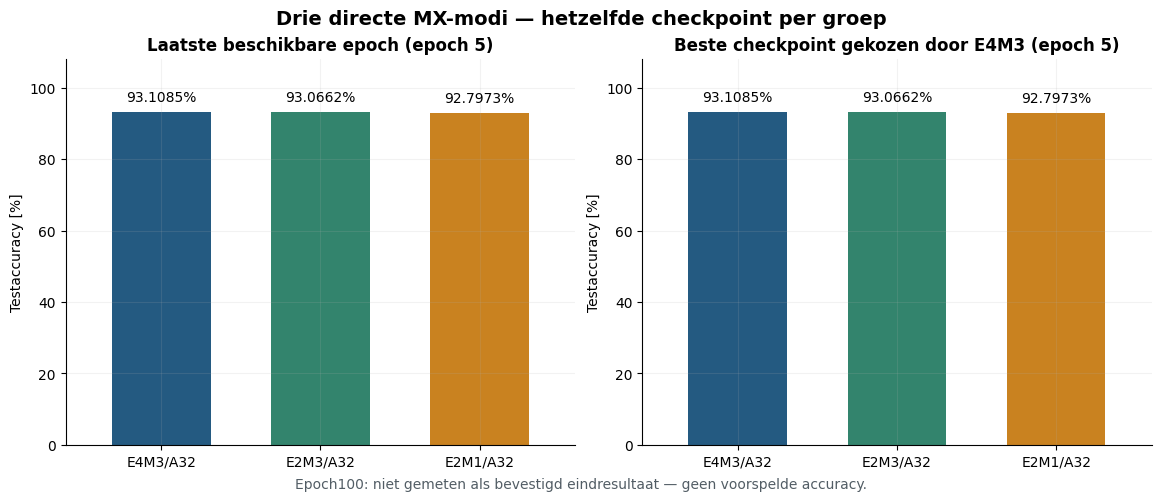

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Train- en testaccuracy per modus

Trainaccuracy is tijdens de gezamenlijke updates verzameld. Testaccuracy wordt na iedere epoch met bevroren evaluatiestaat gemeten, op dezelfde volledige testset voor alle modi. De figuren tonen uitsluitend opgeslagen epochs.


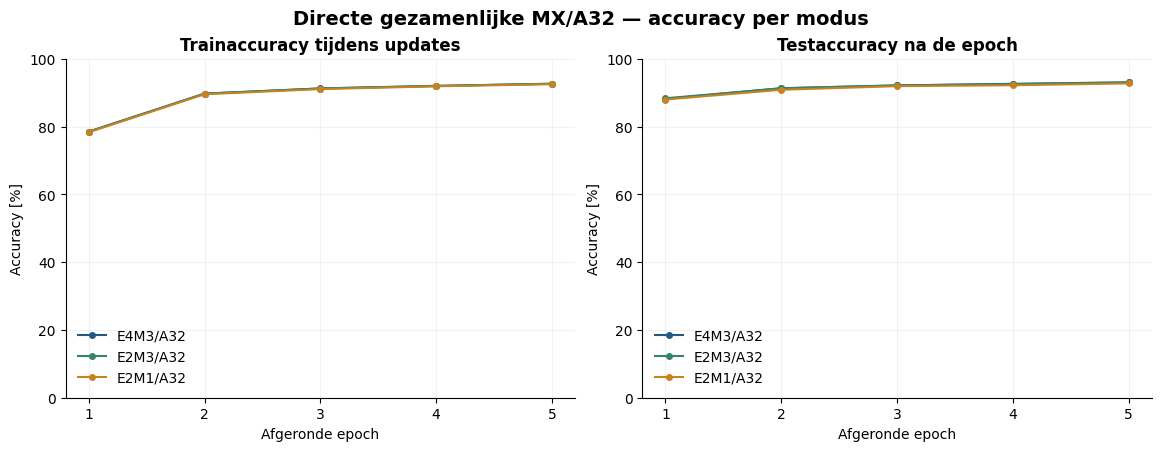

In [4]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.822902
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.771229
2,1,train,MXFP8_E4M3,hard_cross_entropy,0.664960
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.395795
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.385497
5,1,test,MXFP8_E4M3,hard_cross_entropy,0.388447
6,2,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.436311
7,2,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.388674
8,2,train,MXFP8_E4M3,hard_cross_entropy,0.337786
9,2,test,MXFP4_E2M1,hard_cross_entropy,0.308565


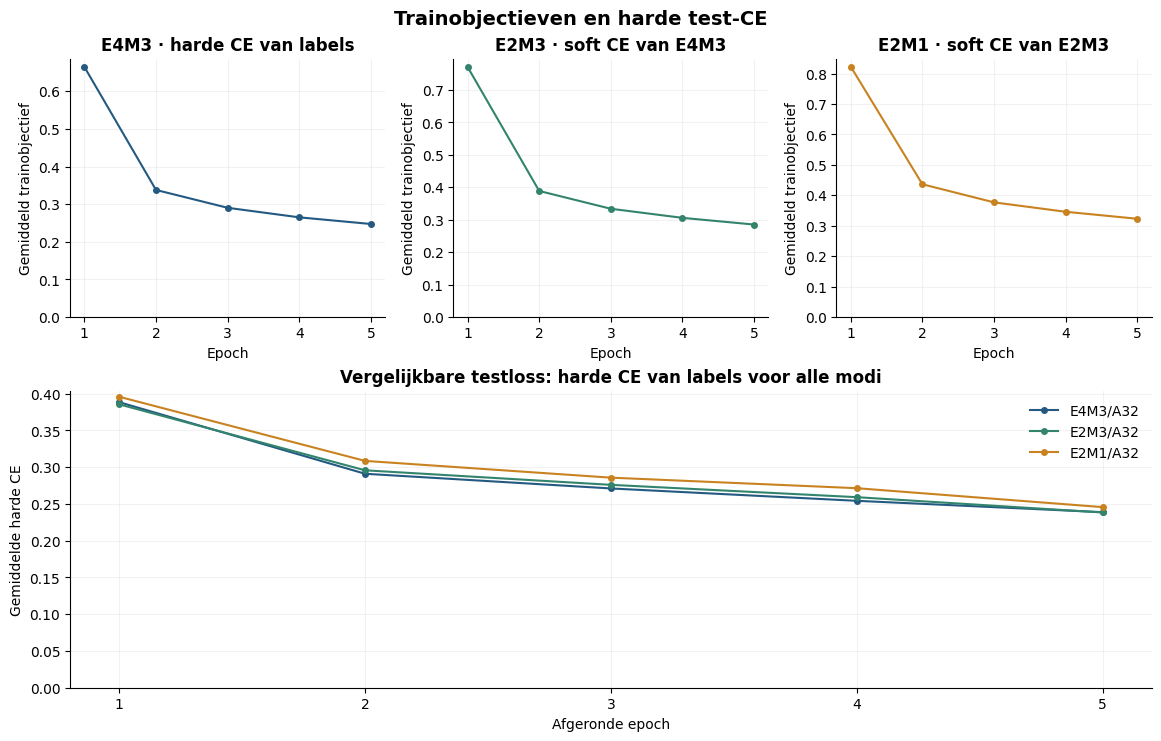

In [5]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Gemeten pilotduur en afzonderlijke honderd-epochprojectie

**Gemeten som over 5 afgeronde epochs: 315.58 s (5.26 minuten).** Warme epochs volgens het tijdsrapport: **[2, 3, 4, 5]**; mediaan: **63.8 s**. De afzonderlijke projectie geldt voor een **nieuwe volledige run van honderd epochs vanaf initialisatie**. Zij is geen gemeten eindtijd en geen resterende hervattijd. Het waargenomen minimum/maximum van de warme epochs levert een scenario-bereik, geen betrouwbaarheidsinterval. Vijf epochs meten de LR-overgangen op 50/75/90 en langdurige thermische omstandigheden nog niet. Download, installatie, data-inladen en eindrapportage zijn niet inbegrepen. **Geen accuracy voor epoch100 wordt voorspeld.**

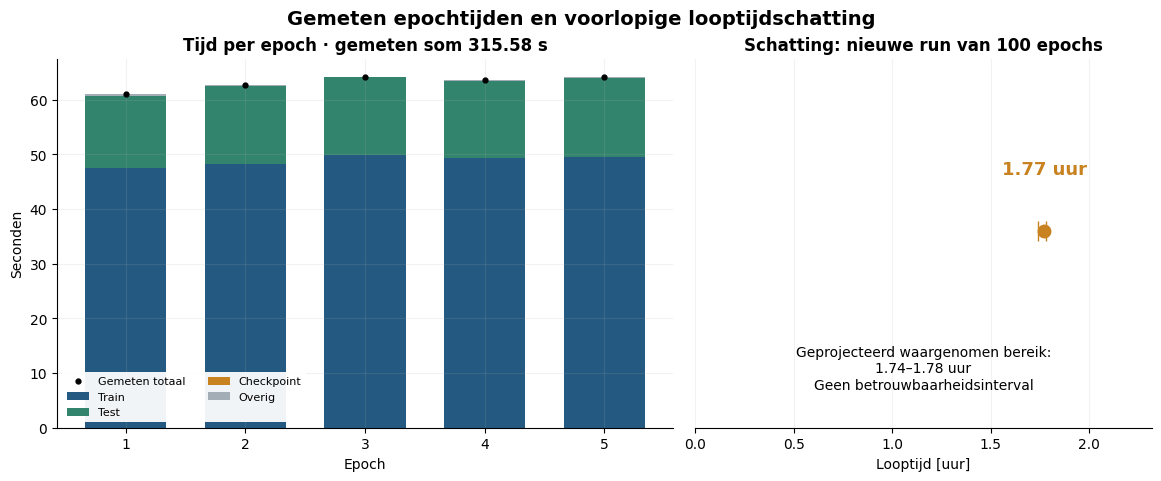

In [6]:
display(Markdown('## Gemeten pilotduur en afzonderlijke honderd-epochprojectie'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

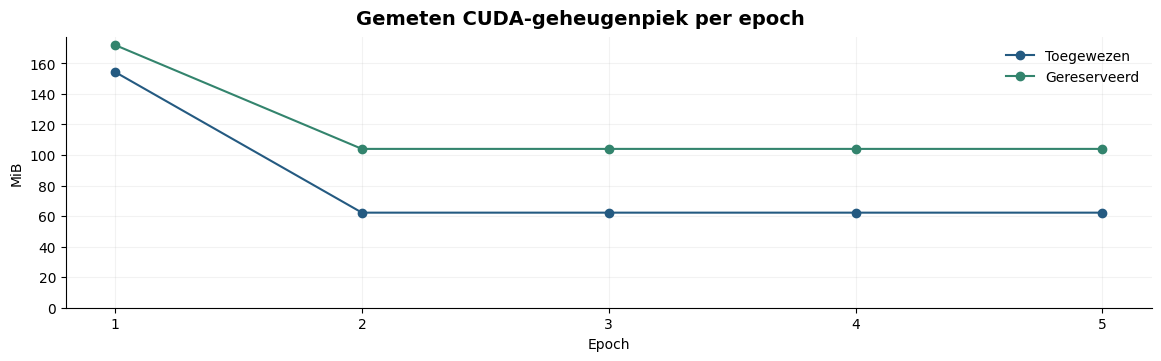

In [7]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [8]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Directe exports per formaat en geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten geverifieerd,True
2,BN-tellers van alle opgeslagen epochs correct,True
3,Geen optimizerupdates tijdens evaluatie,True
4,Bronbestanden onveranderd,True
5,Ruwe datasetbestanden onveranderd,True
6,Gezamenlijke optimizerupdates,2865
7,Trainforwardpasses; verwacht driemaal updates,8595
8,Alle modi van hetzelfde geselecteerde checkpoint,True
9,Selectie op officiële testset,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,1.208228,torch.float32,1362,2
1,1,MXFP6_E2M3,layers.3,1728,1.208228,torch.float32,1614,2
2,1,MXFP8_E4M3,layers.3,1728,1.208228,torch.float32,1622,2
3,1,MXFP4_E2M1,layers.6,2304,1.438102,torch.float32,1858,1
4,1,MXFP6_E2M3,layers.6,2304,1.438102,torch.float32,2176,1
...,...,...,...,...,...,...,...,...
85,5,MXFP6_E2M3,layers.16,9216,1.335037,torch.float32,7989,26
86,5,MXFP8_E4M3,layers.16,9216,1.335037,torch.float32,8162,26
87,5,MXFP4_E2M1,layers.20,99086,5.250870,torch.float32,62902,422
88,5,MXFP6_E2M3,layers.20,99086,5.250870,torch.float32,87478,422


### Directe exports per formaat en geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes FP32-masters afwezig,Volledige exporttest opnieuw,Truncatie
0,best_E4M3_test,5,MXFP8_E4M3,mx_direct_MXFP8_E4M3_best.pt,196517,True,True,False,False
1,best_E4M3_test,5,MXFP6_E2M3,mx_direct_MXFP6_E2M3_best.pt,163941,True,True,False,False
2,best_E4M3_test,5,MXFP4_E2M1,mx_direct_MXFP4_E2M1_best.pt,131301,True,True,False,False
3,last_epoch,5,MXFP8_E4M3,mx_direct_MXFP8_E4M3_last.pt,196517,True,True,False,False
4,last_epoch,5,MXFP6_E2M3,mx_direct_MXFP6_E2M3_last.pt,163941,True,True,False,False
5,last_epoch,5,MXFP4_E2M1,mx_direct_MXFP4_E2M1_last.pt,131301,True,True,False,False


## Interpretatie en grenzen

Deze pilot controleert uitvoerbaarheid, numeriek gedrag en tijd van gezamenlijke directe kwantisatie. De drie uitvoermodi zijn drie rechtstreeks afgeronde representaties, elk met de eigen standaard schaalkeuze. Er is geen bewijs geleverd dat alleen de hoogste opgeslagen MX-representatie alle modi kan voeden. De exporttabel maakt zichtbaar of alleen de gedecodeerde gewichten zijn vergeleken of ook een volledige testpass is herhaald.

A32 en FP32 beschrijven de activatie- en masterdtypes. De opgeslagen CUDA-backendprecisie staat apart in de protocoltabel; cuDNN kan intern TF32 gebruiken. De emulator meet geen native MX-snelheid of energie. Deze pilot verandert de oudere dedicated, directe tweemodus- en mantissatruncatieresultaten niet.

`SAVE_FIGURES = True` schrijft uitsluitend de vijf figuren en een analysemanifest naar een **nieuwe** map. De runner kan dit voor de runkopie inschakelen. Elke uitvoering maakt een nieuwe map; JSON, CSV, checkpoints en eerdere analyses blijven ongewijzigd.


In [9]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [path.name for path in run.input_files]}))


Figuren opgeslagen in: C:\Users\renzo\master-thesis-mx\mx_runs\mx_weights_triple_direct_pilot5\20261023_144246_066123_joint_run\analysis_20261023_145721_698581
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_weights_triple_direct_pilot5\20261023_144246_066123_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
